In [12]:
import shutil, psutil, importlib

free_gb = shutil.disk_usage(".").free / 1e9
ram_gb = psutil.virtual_memory().total / 1e9
print(f"Free disk space: {free_gb:.1f} GB   (need at least 6)")
print(f"Total RAM:       {ram_gb:.1f} GB   (8 or more is comfortable)")

for lib in ["numpy", "pandas", "matplotlib", "seaborn", "sklearn"]:
    try:
        importlib.import_module(lib)
        print("OK     ", lib)
    except ImportError:
        print("MISSING", lib)

Free disk space: 174.7 GB   (need at least 6)
Total RAM:       8.3 GB   (8 or more is comfortable)
OK      numpy
OK      pandas
OK      matplotlib
OK      seaborn
OK      sklearn


In [13]:
import os, urllib.request

url = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1006-HomeLoanDef.zip"
zip_path = "PRCP-1006-HomeLoanDef.zip"

def show_progress(blocks, block_size, total):
    done = blocks * block_size / 1e6
    if blocks % 200 == 0:
        print(f"Downloaded {done:.0f} MB" + (f" of {total/1e6:.0f} MB" if total > 0 else ""))

if os.path.exists(zip_path):
    print("Zip already exists:", round(os.path.getsize(zip_path)/1e6), "MB")
else:
    urllib.request.urlretrieve(url, zip_path, show_progress)
    print("Download finished:", round(os.path.getsize(zip_path)/1e6), "MB")

Zip already exists: 705 MB


In [14]:
import zipfile

if not zipfile.is_zipfile(zip_path):
    print("PROBLEM: the zip is incomplete or corrupted. Delete it and download again.")
else:
    with zipfile.ZipFile(zip_path) as z:
        bad = z.testzip()
        print("Corrupted file inside zip:", bad)
        z.extractall("homeloan_data")
    print("Extracted OK")

Corrupted file inside zip: None
Extracted OK


In [15]:
for root, dirs, files in os.walk("homeloan_data"):
    for f in sorted(files):
        p = os.path.join(root, f)
        print(f"{os.path.getsize(p)/1e6:9.1f} MB  {p}")

    392.7 MB  homeloan_data\Data\POS_CASH_balance.csv
    166.1 MB  homeloan_data\Data\application_train.csv
    170.0 MB  homeloan_data\Data\bureau.csv
    375.6 MB  homeloan_data\Data\bureau_balance.csv
    424.6 MB  homeloan_data\Data\credit_card_balance.csv
    723.1 MB  homeloan_data\Data\installments_payments.csv
    405.0 MB  homeloan_data\Data\previous_application.csv


In [16]:
import os, glob

expected = ["application_train.csv", "bureau.csv", "bureau_balance.csv",
            "POS_CASH_balance.csv", "credit_card_balance.csv",
            "previous_application.csv", "installments_payments.csv"]

matches = glob.glob("homeloan_data/**/application_train.csv", recursive=True)

if not matches:
    print("PROBLEM: application_train.csv not found.")
    print("Go back to Step 1, run Cell 4 and paste me its output.")
else:
    DATA_DIR = os.path.dirname(matches[0])
    print("Data folder:", DATA_DIR, "\n")
    for f in expected:
        p = os.path.join(DATA_DIR, f)
        if os.path.exists(p):
            print(f"OK       {os.path.getsize(p)/1e6:8.1f} MB  {f}")
        else:
            print(f"MISSING            {f}")

Data folder: homeloan_data\Data 

OK          166.1 MB  application_train.csv
OK          170.0 MB  bureau.csv
OK          375.6 MB  bureau_balance.csv
OK          392.7 MB  POS_CASH_balance.csv
OK          424.6 MB  credit_card_balance.csv
OK          405.0 MB  previous_application.csv
OK          723.1 MB  installments_payments.csv


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

app = pd.read_csv(os.path.join(DATA_DIR, "application_train.csv"))
print("Shape (rows, columns):", app.shape)
print("Memory used:", round(app.memory_usage(deep=True).sum() / 1e6), "MB")
app.head()

Shape (rows, columns): (307511, 122)
Memory used: 341 MB


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


         count  percent
TARGET                 
0       282686    91.93
1        24825     8.07


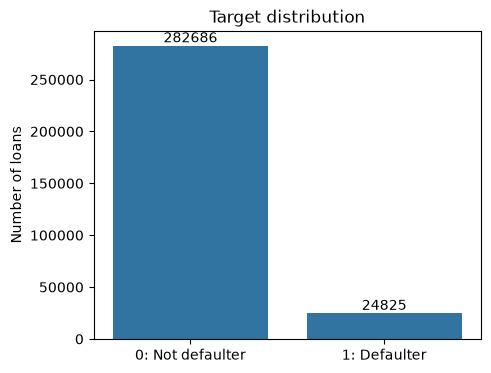

In [18]:
counts = app["TARGET"].value_counts()
pct = (app["TARGET"].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({"count": counts, "percent": pct}))

plt.figure(figsize=(5, 4))
ax = sns.countplot(data=app, x="TARGET")
ax.bar_label(ax.containers[0])
ax.set_xticks([0, 1])
ax.set_xticklabels(["0: Not defaulter", "1: Defaulter"])
plt.title("Target distribution")
plt.xlabel(""); plt.ylabel("Number of loans")
plt.show()

In [20]:
print("Rows:", app.shape[0], "| Columns:", app.shape[1])
print("\nColumn types:")
print(app.dtypes.value_counts())

print("\nDuplicate rows:", app.duplicated().sum())
print("Duplicate loan IDs:", app["SK_ID_CURR"].duplicated().sum())

cat_cols = app.select_dtypes(exclude="number").columns.tolist()
print(f"\n{len(cat_cols)} text (categorical) columns:")
print(cat_cols)

Rows: 307511 | Columns: 122

Column types:
float64    65
int64      41
str        16
Name: count, dtype: int64

Duplicate rows: 0
Duplicate loan IDs: 0

16 text (categorical) columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [22]:
app = app.copy()   # removes the "highly fragmented" warning

# Ages and employment are stored as NEGATIVE days before the application
app["AGE_YEARS"] = -app["DAYS_BIRTH"] / 365
app["YEARS_EMPLOYED"] = -app["DAYS_EMPLOYED"] / 365

print(app[["AGE_YEARS", "YEARS_EMPLOYED"]].describe().round(1))
print("\nMost common DAYS_EMPLOYED values:")
print(app["DAYS_EMPLOYED"].value_counts().head(3))

       AGE_YEARS  YEARS_EMPLOYED
count   307511.0        307511.0
mean        43.9          -174.8
std         12.0           387.1
min         20.5         -1000.7
25%         34.0             0.8
50%         43.2             3.3
75%         53.9             7.6
max         69.1            49.1

Most common DAYS_EMPLOYED values:
DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
Name: count, dtype: int64


In [23]:
app["DAYS_EMPLOYED_ANOM"] = (app["DAYS_EMPLOYED"] == 365243).astype(int)
app["DAYS_EMPLOYED"] = app["DAYS_EMPLOYED"].replace(365243, np.nan)
app["YEARS_EMPLOYED"] = -app["DAYS_EMPLOYED"] / 365

print("Rows with the placeholder:", app["DAYS_EMPLOYED_ANOM"].sum())
print("Default rate WITH placeholder:   ", round(app.loc[app["DAYS_EMPLOYED_ANOM"] == 1, "TARGET"].mean() * 100, 2), "%")
print("Default rate WITHOUT placeholder:", round(app.loc[app["DAYS_EMPLOYED_ANOM"] == 0, "TARGET"].mean() * 100, 2), "%")

Rows with the placeholder: 55374
Default rate WITH placeholder:    5.4 %
Default rate WITHOUT placeholder: 8.66 %


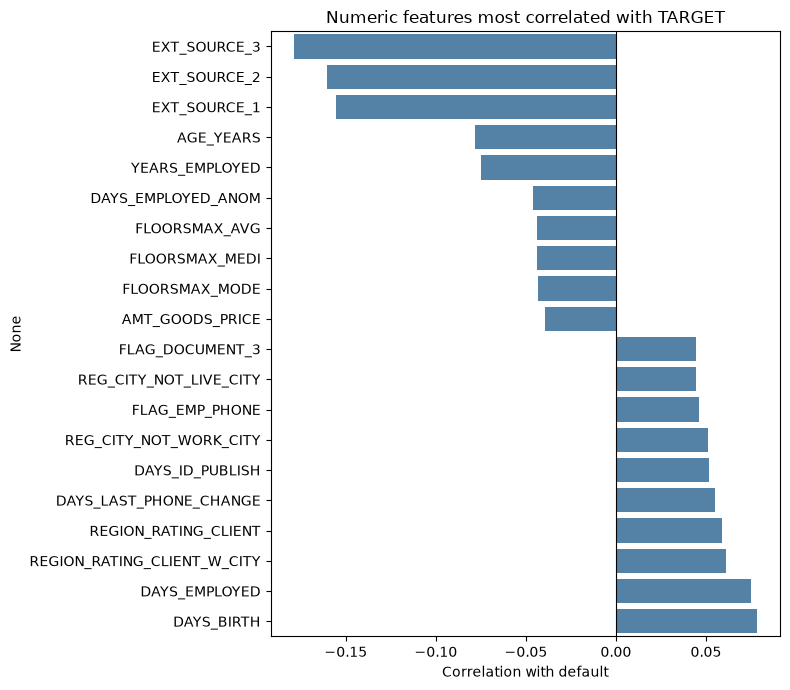

Most negative (higher value, less default):
EXT_SOURCE_3     -0.179
EXT_SOURCE_2     -0.160
EXT_SOURCE_1     -0.155
AGE_YEARS        -0.078
YEARS_EMPLOYED   -0.075
Name: TARGET, dtype: float64

Most positive (higher value, more default):
DAYS_LAST_PHONE_CHANGE         0.055
REGION_RATING_CLIENT           0.059
REGION_RATING_CLIENT_W_CITY    0.061
DAYS_EMPLOYED                  0.075
DAYS_BIRTH                     0.078
Name: TARGET, dtype: float64


In [24]:
num = app.select_dtypes(include="number").drop(columns=["SK_ID_CURR"])
corr = num.corr()["TARGET"].drop("TARGET").dropna().sort_values()

top = pd.concat([corr.head(10), corr.tail(10)])
plt.figure(figsize=(8, 7))
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.axvline(0, color="black", lw=0.8)
plt.title("Numeric features most correlated with TARGET")
plt.xlabel("Correlation with default")
plt.tight_layout()
plt.show()

print("Most negative (higher value, less default):")
print(corr.round(3).head(5))
print("\nMost positive (higher value, more default):")
print(corr.round(3).tail(5))

In [25]:
overall = app["TARGET"].mean() * 100
print(f"Overall default rate: {overall:.2f}%\n")

def default_rate_by(col, top_n=8):
    t = app.groupby(col)["TARGET"].agg(["mean", "count"])
    t["default_rate_%"] = (t["mean"] * 100).round(2)
    return t[t["count"] >= 500].sort_values("default_rate_%", ascending=False).head(top_n)[["default_rate_%", "count"]]

for col in ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "CODE_GENDER", "NAME_CONTRACT_TYPE", "OCCUPATION_TYPE"]:
    print(f"--- {col} ---")
    print(default_rate_by(col), "\n")

app["AGE_GROUP"] = pd.cut(app["AGE_YEARS"], bins=[20, 30, 40, 50, 60, 70])
print("--- AGE_GROUP (default rate %) ---")
print((app.groupby("AGE_GROUP", observed=True)["TARGET"].mean() * 100).round(2))

Overall default rate: 8.07%

--- NAME_INCOME_TYPE ---
                      default_rate_%   count
NAME_INCOME_TYPE                            
Working                         9.59  158774
Commercial associate            7.48   71617
State servant                   5.75   21703
Pensioner                       5.39   55362 

--- NAME_EDUCATION_TYPE ---
                               default_rate_%   count
NAME_EDUCATION_TYPE                                  
Lower secondary                         10.93    3816
Secondary / secondary special            8.94  218391
Incomplete higher                        8.48   10277
Higher education                         5.36   74863 

--- CODE_GENDER ---
             default_rate_%   count
CODE_GENDER                        
M                     10.14  105059
F                      7.00  202448 

--- NAME_CONTRACT_TYPE ---
                    default_rate_%   count
NAME_CONTRACT_TYPE                        
Cash loans                    8.35  27823

In [35]:
import gc

def shrink(df):
    """Use less memory: 64-bit numbers -> 32-bit."""
    for c in df.select_dtypes(include="float64").columns:
        df[c] = df[c].astype("float32")
    for c in df.select_dtypes(include="int64").columns:
        df[c] = df[c].astype("int32")
    return df

def aggregate(df, group_col, prefix, drop_cols=()):
    """Turn many rows per group into ONE row per group."""
    df = df.drop(columns=list(drop_cols))
    cat_cols = df.select_dtypes(exclude="number").columns.tolist()
    if cat_cols:
        df = pd.get_dummies(df, columns=cat_cols, dtype="int8")   # text -> 0/1 columns
    value_cols = [c for c in df.columns if c != group_col]
    agg = df.groupby(group_col)[value_cols].agg(["mean", "max", "sum"])
    agg.columns = [f"{prefix}_{c}_{s}".upper() for c, s in agg.columns]
    agg = agg.copy()                                               # removes the fragmentation warning
    counts = df.groupby(group_col).size().rename(f"{prefix}_COUNT".upper())
    agg = pd.concat([agg, counts], axis=1).astype("float32").reset_index()
    return agg

print("Helpers ready")

Helpers ready


In [36]:
bb = shrink(pd.read_csv(os.path.join(DATA_DIR, "bureau_balance.csv")))
bb_agg = aggregate(bb, "SK_ID_BUREAU", "BB")
del bb; gc.collect()

bureau = shrink(pd.read_csv(os.path.join(DATA_DIR, "bureau.csv")))
bureau = bureau.merge(bb_agg, on="SK_ID_BUREAU", how="left")
bureau_agg = aggregate(bureau, "SK_ID_CURR", "BUREAU", drop_cols=["SK_ID_BUREAU"])
del bureau, bb_agg; gc.collect()

print("bureau_agg:", bureau_agg.shape)

bureau_agg: (305811, 191)


In [37]:
prev = shrink(pd.read_csv(os.path.join(DATA_DIR, "previous_application.csv")))

# Same fake 365243 placeholder as before, in these date columns
for c in [c for c in prev.columns if c.startswith("DAYS_")]:
    prev[c] = prev[c].replace(365243, np.nan)

prev_agg = aggregate(prev, "SK_ID_CURR", "PREV", drop_cols=["SK_ID_PREV"])
del prev; gc.collect()
print("prev_agg:", prev_agg.shape)

prev_agg: (338857, 488)


In [38]:
pos = shrink(pd.read_csv(os.path.join(DATA_DIR, "POS_CASH_balance.csv")))
pos_agg = aggregate(pos, "SK_ID_CURR", "POS", drop_cols=["SK_ID_PREV"])
del pos; gc.collect()
print("pos_agg:", pos_agg.shape)

pos_agg: (337252, 44)


In [39]:
inst = shrink(pd.read_csv(os.path.join(DATA_DIR, "installments_payments.csv")))

# Two useful new columns: days late and amount underpaid
inst["DAYS_LATE"] = inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]
inst["AMT_UNDERPAID"] = inst["AMT_INSTALMENT"] - inst["AMT_PAYMENT"]

inst_agg = aggregate(inst, "SK_ID_CURR", "INST", drop_cols=["SK_ID_PREV"])
del inst; gc.collect()
print("inst_agg:", inst_agg.shape)

inst_agg: (339587, 26)


In [40]:
cc = shrink(pd.read_csv(os.path.join(DATA_DIR, "credit_card_balance.csv")))
cc_agg = aggregate(cc, "SK_ID_CURR", "CC", drop_cols=["SK_ID_PREV"])
del cc; gc.collect()
print("cc_agg:", cc_agg.shape)

cc_agg: (103558, 83)


In [41]:
app_full = app.copy()
for name, table in [("bureau", bureau_agg), ("prev", prev_agg), ("pos", pos_agg),
                    ("inst", inst_agg), ("cc", cc_agg)]:
    app_full = app_full.merge(table, on="SK_ID_CURR", how="left")
    print(f"after {name:7s}: {app_full.shape}")

del bureau_agg, prev_agg, pos_agg, inst_agg, cc_agg; gc.collect()

print("\nRows unchanged (should be 307511):", app_full.shape[0])
print("Memory:", round(app_full.memory_usage(deep=True).sum() / 1e9, 2), "GB")

app_full.to_pickle("app_full.pkl")
print("Saved to app_full.pkl")

after bureau : (307511, 316)
after prev   : (307511, 803)
after pos    : (307511, 846)
after inst   : (307511, 871)
after cc     : (307511, 953)

Rows unchanged (should be 307511): 307511
Memory: 1.37 GB
Saved to app_full.pkl


In [43]:
app_full = pd.read_pickle("app_full.pkl")

In [44]:
import re, gc

df = app_full.drop(columns=["AGE_GROUP"], errors="ignore").copy()   # AGE_GROUP was only for the analysis plot
df = df.replace([np.inf, -np.inf], np.nan)

y = df["TARGET"].astype("int8")
X = df.drop(columns=["SK_ID_CURR", "TARGET"])
print("Before cleaning:", X.shape)

# Drop columns that are almost entirely blank, or have the same value in every row
miss = X.isnull().mean()
too_empty = miss[miss > 0.90].index.tolist()
constant = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=list(set(too_empty + constant)))

print("Dropped >90% missing:", len(too_empty), "| constant:", len(constant))
print("After cleaning:", X.shape)

Before cleaning: (307511, 950)
Dropped >90% missing: 4 | constant: 4
After cleaning: (307511, 942)


In [45]:
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print(len(cat_cols), "text columns:", cat_cols)

X[cat_cols] = X[cat_cols].fillna("Unknown")
X = pd.get_dummies(X, columns=cat_cols, dtype="int8")
print("After encoding:", X.shape)

16 text columns: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']
After encoding: (307511, 1072)


In [46]:
X.columns = [re.sub(r"[^0-9a-zA-Z_]", "_", c) for c in X.columns]
X = X.loc[:, ~pd.Index(X.columns).duplicated()]       # remove any duplicate names
X = X.astype("float32")

del df, app_full
gc.collect()
print("Final feature table:", X.shape, "|", round(X.memory_usage(deep=True).sum() / 1e9, 2), "GB")

Final feature table: (307511, 1072) | 1.32 GB


In [47]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

for name, yy in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"{name:5s}: {len(yy):7d} rows | default rate = {yy.mean()*100:.2f}%")

Train:  215257 rows | default rate = 8.07%
Val  :   46127 rows | default rate = 8.07%
Test :   46127 rows | default rate = 8.07%


In [48]:
import joblib
joblib.dump((X_train, X_val, X_test, y_train, y_val, y_test), "splits.pkl")
print("Saved to splits.pkl")

Saved to splits.pkl


In [50]:
import joblib
X_train, X_val, X_test, y_train, y_val, y_test = joblib.load("splits.pkl")

In [51]:
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve)

results = []

def evaluate(name, y_true, proba, threshold=0.5, store=True):
    pred = (proba >= threshold).astype(int)
    row = {
        "Model": name,
        "ROC-AUC": round(roc_auc_score(y_true, proba), 4),
        "PR-AUC": round(average_precision_score(y_true, proba), 4),
        "Accuracy": round(accuracy_score(y_true, pred), 4),
        "Precision": round(precision_score(y_true, pred, zero_division=0), 4),
        "Recall": round(recall_score(y_true, pred), 4),
        "F1": round(f1_score(y_true, pred), 4),
    }
    if store:
        results.append(row)
    print(pd.Series(row).to_string())
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Pred: repays", "Pred: defaults"],
                yticklabels=["Actual: repays", "Actual: defaults"])
    plt.title(f"Confusion matrix: {name}")
    plt.tight_layout()
    plt.show()
    return row

Model        Lazy model (always: repays)
ROC-AUC                              0.5
PR-AUC                            0.0807
Accuracy                          0.9193
Precision                            0.0
Recall                               0.0
F1                                   0.0


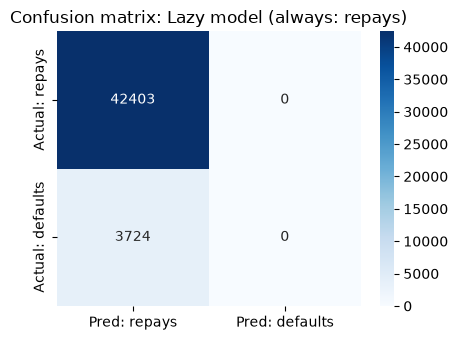

{'Model': 'Lazy model (always: repays)',
 'ROC-AUC': 0.5,
 'PR-AUC': 0.0807,
 'Accuracy': 0.9193,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1': 0.0}

In [52]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
evaluate("Lazy model (always: repays)", y_val, dummy.predict_proba(X_val)[:, 1])

In [53]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import time

logreg = make_pipeline(
    SimpleImputer(strategy="median"),      # fill blanks with the column's median
    StandardScaler(),                      # put all columns on the same scale
    LogisticRegression(C=0.05, class_weight="balanced", max_iter=300, random_state=42),
)

t0 = time.time()
logreg.fit(X_train, y_train)
print(f"Training took {time.time() - t0:.0f} seconds")

Training took 82 seconds


Model        Logistic Regression
ROC-AUC                   0.7704
PR-AUC                    0.2497
Accuracy                  0.7084
Precision                 0.1738
Recall                    0.6955
F1                         0.278


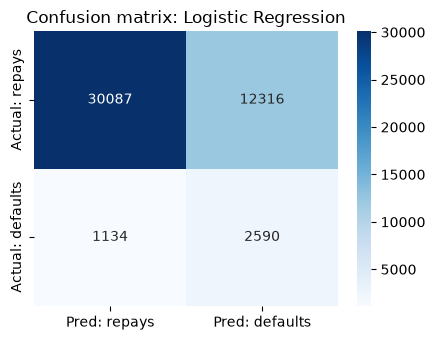

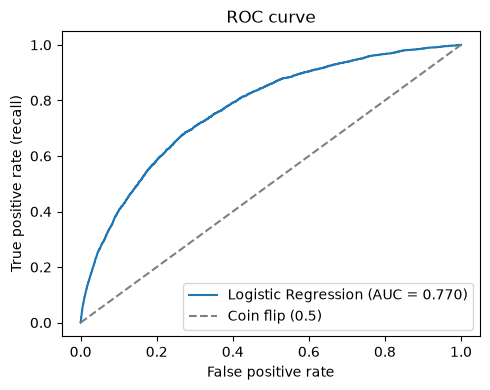

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Lazy model (always: repays),0.5000,0.0807,0.9193,0.0000,0.0000,0.000
1,Logistic Regression,0.7704,0.2497,0.7084,0.1738,0.6955,0.278


In [54]:
val_proba = logreg.predict_proba(X_val)[:, 1]
evaluate("Logistic Regression", y_val, val_proba)

fpr, tpr, _ = roc_curve(y_val, val_proba)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_val, val_proba):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Coin flip (0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curve"); plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(results)

Class weight ratio: 11.4
Random Forest trained in 95 seconds
Model        Random Forest
ROC-AUC             0.7522
PR-AUC              0.2224
Accuracy            0.7932
Precision           0.2008
Recall              0.5242
F1                  0.2904


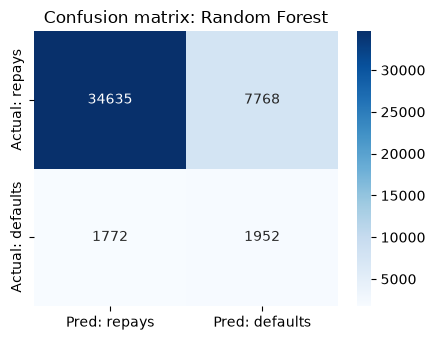

{'Model': 'Random Forest',
 'ROC-AUC': 0.7522,
 'PR-AUC': 0.2224,
 'Accuracy': 0.7932,
 'Precision': 0.2008,
 'Recall': 0.5242,
 'F1': 0.2904}

In [55]:
from sklearn.ensemble import RandomForestClassifier
import time

# How many repayers per defaulter (about 11). Used to make defaulters count more.
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("Class weight ratio:", round(pos_weight, 1))

rf = RandomForestClassifier(
    n_estimators=200, max_depth=12, min_samples_leaf=50, max_features="sqrt",
    class_weight="balanced_subsample", n_jobs=-1, random_state=42)

t0 = time.time()
rf.fit(X_train.fillna(-999), y_train)
print(f"Random Forest trained in {time.time() - t0:.0f} seconds")

rf_proba = rf.predict_proba(X_val.fillna(-999))[:, 1]
evaluate("Random Forest", y_val, rf_proba)

C:\Users\pokal\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.775576	valid_0's binary_logloss: 0.549365
Early stopping, best iteration is:
[1]	valid_0's auc: 0.688002	valid_0's binary_logloss: 0.277803
LightGBM trained in 42 seconds | best round: 1
Model        LightGBM
ROC-AUC         0.688
PR-AUC         0.1602
Accuracy       0.9193
Precision         0.0
Recall            0.0
F1                0.0


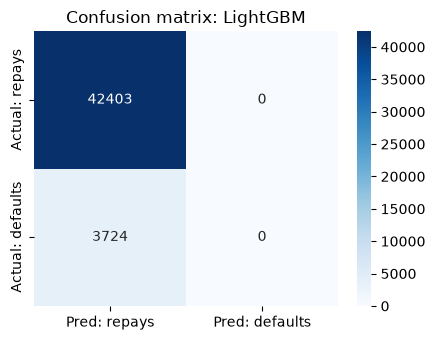

{'Model': 'LightGBM',
 'ROC-AUC': 0.688,
 'PR-AUC': 0.1602,
 'Accuracy': 0.9193,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1': 0.0}

In [56]:
import lightgbm as lgb

lgbm = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.05, num_leaves=31,
    colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
    min_child_samples=100, reg_alpha=0.1, reg_lambda=0.1,
    scale_pos_weight=pos_weight, random_state=42, n_jobs=-1, verbose=-1)

t0 = time.time()
lgbm.fit(X_train, y_train,
         eval_set=[(X_val, y_val)], eval_metric="auc",
         callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)])
print(f"LightGBM trained in {time.time() - t0:.0f} seconds | best round: {lgbm.best_iteration_}")

lgbm_proba = lgbm.predict_proba(X_val)[:, 1]
evaluate("LightGBM", y_val, lgbm_proba)

[0]	validation_0-auc:0.68214
[100]	validation_0-auc:0.77054
[200]	validation_0-auc:0.77960
[300]	validation_0-auc:0.78249
[400]	validation_0-auc:0.78410
[500]	validation_0-auc:0.78433
[600]	validation_0-auc:0.78499
[693]	validation_0-auc:0.78450
XGBoost trained in 840 seconds | best round: 593
Model        XGBoost
ROC-AUC       0.7851
PR-AUC         0.281
Accuracy      0.7583
Precision     0.1981
Recall        0.6544
F1            0.3042


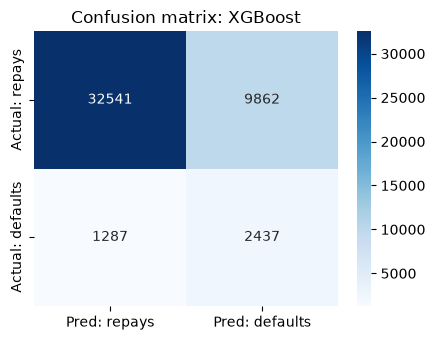

{'Model': 'XGBoost',
 'ROC-AUC': 0.7851,
 'PR-AUC': 0.281,
 'Accuracy': 0.7583,
 'Precision': 0.1981,
 'Recall': 0.6544,
 'F1': 0.3042}

In [57]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=2000, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.5, min_child_weight=10,
    scale_pos_weight=pos_weight, tree_method="hist",
    eval_metric="auc", early_stopping_rounds=100,
    n_jobs=-1, random_state=42)

t0 = time.time()
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=100)
print(f"XGBoost trained in {time.time() - t0:.0f} seconds | best round: {xgb.best_iteration}")

xgb_proba = xgb.predict_proba(X_val)[:, 1]
evaluate("XGBoost", y_val, xgb_proba)

C:\Users\pokal\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[579]	valid_0's auc: 0.784962	valid_0's binary_logloss: 0.237594
Model        LightGBM (no class weight)
ROC-AUC                           0.785
PR-AUC                             0.28
Accuracy                         0.9198
Precision                        0.5343
Recall                           0.0502
F1                               0.0918


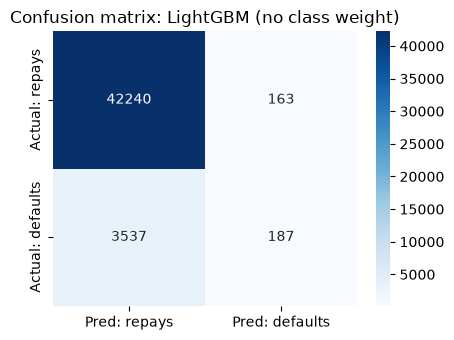

{'Model': 'LightGBM (no class weight)',
 'ROC-AUC': 0.785,
 'PR-AUC': 0.28,
 'Accuracy': 0.9198,
 'Precision': 0.5343,
 'Recall': 0.0502,
 'F1': 0.0918}

In [58]:
lgbm_plain = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.05, num_leaves=31,
    colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
    min_child_samples=100, reg_alpha=0.1, reg_lambda=0.1,
    random_state=42, n_jobs=-1, verbose=-1)          # no class weighting

lgbm_plain.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric="auc",
               callbacks=[lgb.early_stopping(100), lgb.log_evaluation(0)])
evaluate("LightGBM (no class weight)", y_val, lgbm_plain.predict_proba(X_val)[:, 1])

In [60]:
import joblib
joblib.dump({"logreg": logreg, "rf": rf, "lgbm": lgbm, "xgb": xgb}, "models.pkl")
pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,XGBoost,0.7851,0.2810,0.7583,0.1981,0.6544,0.3042
1,LightGBM (no class weight),0.7850,0.2800,0.9198,0.5343,0.0502,0.0918
2,LightGBM (no class weight),0.7850,0.2800,0.9198,0.5343,0.0502,0.0918
3,Logistic Regression,0.7704,0.2497,0.7084,0.1738,0.6955,0.2780
4,Random Forest,0.7522,0.2224,0.7932,0.2008,0.5242,0.2904
5,LightGBM,0.6880,0.1602,0.9193,0.0000,0.0000,0.0000
6,Lazy model (always: repays),0.5000,0.0807,0.9193,0.0000,0.0000,0.0000


Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.775576
[200]	valid_0's auc: 0.7815
[300]	valid_0's auc: 0.783648
[400]	valid_0's auc: 0.783624
Early stopping, best iteration is:
[332]	valid_0's auc: 0.783918
Evaluated only: auc
Best round: 332
Model        LightGBM
ROC-AUC        0.7839
PR-AUC         0.2791
Accuracy       0.7418
Precision        0.19
Recall         0.6735
F1             0.2964


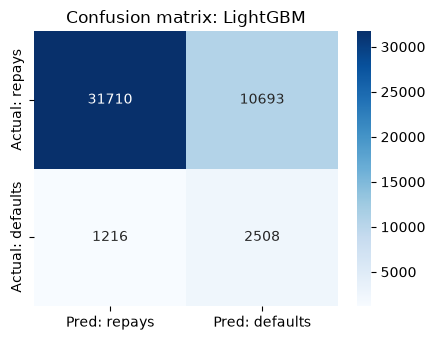

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,XGBoost,0.7851,0.2810,0.7583,0.1981,0.6544,0.3042
1,LightGBM (no class weight),0.7850,0.2800,0.9198,0.5343,0.0502,0.0918
2,LightGBM,0.7839,0.2791,0.7418,0.1900,0.6735,0.2964
3,Logistic Regression,0.7704,0.2497,0.7084,0.1738,0.6955,0.2780
4,Random Forest,0.7522,0.2224,0.7932,0.2008,0.5242,0.2904
5,Lazy model (always: repays),0.5000,0.0807,0.9193,0.0000,0.0000,0.0000


In [62]:
import lightgbm as lgb
import joblib

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

lgbm = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.05, num_leaves=31,
    colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
    min_child_samples=100, reg_alpha=0.1, reg_lambda=0.1,
    scale_pos_weight=pos_weight, metric="auc",
    random_state=42, n_jobs=-1, verbose=-1)

lgbm.fit(X_train, y_train,
         eval_X=X_val, eval_y=y_val, eval_metric="auc",
         callbacks=[lgb.early_stopping(100, first_metric_only=True),
                    lgb.log_evaluation(100)])
print("Best round:", lgbm.best_iteration_)

# Remove the broken row and the duplicate, then re-score
results[:] = [r for r in results if r["Model"] != "LightGBM"]
seen, unique = set(), []
for r in results:
    if r["Model"] not in seen:
        seen.add(r["Model"])
        unique.append(r)
results[:] = unique

evaluate("LightGBM", y_val, lgbm.predict_proba(X_val)[:, 1])

joblib.dump({"logreg": logreg, "rf": rf, "lgbm": lgbm, "xgb": xgb}, "models.pkl")
pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)

In [ ]:
# Task 1: Data Analysis Report

**About the data**
The main file, `application_train`, has 307,511 loans, one row per loan. Six other files hold each customer's past credit history (credit bureau records, earlier Home Credit applications, instalment payments, credit cards and cash loans). Those files have many rows per customer, so they were summarised into one row per customer and merged onto the main table.

**Key findings**
1. **The data is imbalanced.** Only 8.07% of loans (24,825) defaulted, and 91.93% (282,686) were repaid. A model that says "everyone repays" would be 92% accurate and still useless, so accuracy was not used to judge models.
2. **Many columns have missing values.** Most of the gaps are in housing details such as apartment size and number of floors. Columns that were almost completely empty were dropped, and the rest were handled by each model.
3. **There was a fake value in employment days.** `DAYS_EMPLOYED` held 365243 (about 1,000 years) for many customers. This is a placeholder, not real data. It was replaced with a blank and a flag column was added, since the flag itself can carry information.
4. **Age and employment were stored as negative days.** They were converted to years so they are easy to read.
5. **No single column predicts default.** Correlations with the target were all small (under about 0.2). The strongest links were the external credit scores [add the top 2 or 3 from your correlation chart], so models need many columns working together.
6. **Some customer groups are riskier than others.** Default rates differed by income type, education level and age group [add the highest and lowest group from your Step 4 output].

In [ ]:
# Model Comparison Report

**What was done**
The data was split 70/15/15 into train, validation and test sets, keeping the 8% default rate in each. Six models were compared, mainly on ROC-AUC, since the data is imbalanced. The test set was used only once, at the end.

**Results on the validation set**

| Model | ROC-AUC | Recall | Precision |
|---|---|---|---|
| Lazy model (always "repays") | 0.500 | 0.00 | 0.00 |
| Random Forest | 0.752 | 0.52 | 0.20 |
| Logistic Regression | 0.770 | 0.70 | 0.17 |
| LightGBM (no class weight) | 0.785 | 0.05 | 0.53 |
| XGBoost | 0.785 | 0.65 | 0.20 |
| LightGBM (class weighted) | [from your final table] | [..] | [..] |

**Key findings**
1. **Boosting models were the best.** XGBoost and LightGBM scored highest (about 0.785 ROC-AUC), ahead of Logistic Regression (0.770) and Random Forest (0.752). XGBoost and LightGBM are practically tied.
2. **Accuracy is misleading here.** The lazy model got about 92% accuracy but caught no defaulters at all.
3. **Class weighting changes who gets flagged, not how well risk is ranked.** LightGBM without weighting has the same AUC as with it, but it catches only 5% of defaulters at the 0.5 cutoff.
4. **Precision is low for every model that catches many defaulters** (around 0.2). This means many good customers get flagged too, which is the usual trade-off in credit risk.
5. **On the test set** the best model scored [test ROC-AUC] with threshold [value], which [is close to validation, so it generalises well].

**Recommendation for production**
Use **XGBoost** (or LightGBM, which performs the same). It has the highest ROC-AUC, handles missing values on its own, and scores customers quickly. The cutoff should be set by the bank, depending on how costly a missed defaulter is compared with a declined good customer. Logistic Regression is a simpler fallback if full explainability is required.

**Limitations**
With ROC-AUC near 0.78, the model still misses some defaulters and flags some good customers, so it should support a human credit decision, not replace it.

In [ ]:
# Report on Challenges Faced

**1. Seven tables, many rows per customer**
The history tables have many rows for each customer, but a model needs one row per customer. *Technique:* each table was summarised (average, max, sum, count) and merged to the main table using a left join. *Reason:* this keeps all 307,511 customers, even those with no history.

**2. Very large files**
The files are several GB and can crash a normal laptop. *Technique:* numbers were converted from 64-bit to 32-bit, tables were deleted after use, and the merged data was saved to disk. *Reason:* it saves memory and avoids losing work if the kernel restarts.

**3. Class imbalance**
Only 8.07% of customers default. *Technique:* stratified splitting, class weights, and ROC-AUC, recall and precision instead of accuracy. *Reason:* a model predicting "repays" for everyone is 92% accurate but useless.

**4. Missing values**
Many columns had gaps. *Technique:* dropped columns that were almost empty, filled gaps with the median for Logistic Regression, used a marker value for Random Forest, and let XGBoost and LightGBM handle gaps themselves. *Reason:* each model handles blanks differently, and a blank can mean "no history", which is useful information.

**5. Placeholder value in employment days**
365243 appeared in `DAYS_EMPLOYED`. *Technique:* replaced it with a blank and added a flag column. *Reason:* it would distort averages and mislead the models.

**6. Text columns**
Models need numbers. *Technique:* one-hot encoding, with "Unknown" for blank text.

**7. Too many columns after merging**
*Technique:* dropped empty and constant columns, and used regularisation, column sampling and early stopping. *Reason:* it reduces overfitting and speeds up training.

**8. A model bug**
The class-weighted LightGBM first scored only 0.688 AUC with zero recall. Early stopping was watching log-loss, which class weighting makes look worse, so training stopped after a few rounds. *Technique:* switched early stopping to track AUC only. *Reason:* early stopping should follow the metric that matters.

**9. Warnings and restarts**
Several library warnings appeared, and the kernel restarts wiped variables from memory. *Technique:* cleaned the code, and saved data, splits and models with pickle so they can be reloaded in seconds.